# Logistic regression: classifying the recorded diabetes label

In the earlier notebooks, regression predicted numeric sales. This lesson uses
**binary classification**: predict whether a record has `diabetes = 0` or
`diabetes = 1`. We keep the seven input features chosen in the original notebook.

Each row is one observation. Its seven selected measurements are the **features**;
the `diabetes` column is the **target**. The separate `TenYearCHD` column is not
our target and is not an input in this lesson.

We will inspect the data, handle missing inputs, fit a classifier, compare it with
a majority-class baseline, and interpret probabilities and classification errors.

The CSV does not document how its labels were assigned or when its measurements
were collected. This is an educational model of the recorded label, not a
validated prediction of future diabetes or a clinical decision tool.

## 1. Load and inspect the dataset

Dependencies: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.
Start the kernel in the repository root or a folder inside it. The loader searches
the current folder and its parents and gives an actionable error if the CSV is absent.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
for candidate in (Path.cwd(), *Path.cwd().parents):
    data_path = candidate / "trainingdata" / "framingham.csv"
    if data_path.is_file():
        break
else:
    raise FileNotFoundError(
        "Could not find trainingdata/framingham.csv. Start the kernel "
        "from the How-To-ML repository root or a folder inside it."
    )

df = pd.read_csv(data_path)
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
print(f"Observations: {len(df):,}")
print(f"Columns in the original CSV: {df.shape[1]}")
print(f"Duplicate rows: {df.duplicated().sum()}")

missing_summary = pd.DataFrame(
    {
        "Missing values": df.isna().sum(),
        "Missing (%)": 100 * df.isna().mean(),
    }
)
missing_summary.loc[missing_summary["Missing values"] > 0].round(2)

Observations: 4,238
Columns in the original CSV: 16
Duplicate rows: 0


,Missing values,Missing (%)
education,105,2.48
cigsPerDay,29,0.68
BPMeds,53,1.25
totChol,50,1.18
BMI,19,0.45
heartRate,1,0.02
glucose,388,9.16


## 2. Select features and check the class balance

The seven features describe age, cigarettes per day, total cholesterol, systolic
blood pressure, BMI, heart rate, and glucose. The shape of `X` is `(4238, 7)`:
4,238 observations with seven features each. The target `y` has shape `(4238,)`.

There are 4,129 label-0 records and 109 label-1 records, about 2.57% positives.
This is an **imbalanced** classification problem. Overall accuracy will be
dominated by the many label-0 records, so we also inspect positive-class recall
and precision.

In [4]:
feature_columns = ["age", "cigsPerDay", "totChol", "sysBP", "BMI", "heartRate", "glucose"]
target_column = "diabetes"

if df[target_column].isna().any() or not df[target_column].isin([0, 1]).all():
    raise ValueError("The diabetes target must contain known binary labels 0 and 1.")

X = df[feature_columns].copy()
y = df[target_column].copy()
print(f"Feature shape: {X.shape}; target shape: {y.shape}")
print(f"Rows with at least one missing selected input: {X.isna().any(axis=1).sum()}")

class_counts = y.value_counts().sort_index()
class_summary = pd.DataFrame(
    {"Observations": class_counts, "Percent": 100 * class_counts / len(y)}
)
class_summary.index.name = "Recorded diabetes label"
class_summary.round(2)

Feature shape: (4238, 7); target shape: (4238,)
Rows with at least one missing selected input: 438


,Observations,Percent
Recorded diabetes label,,
0,4129,97.43
1,109,2.57


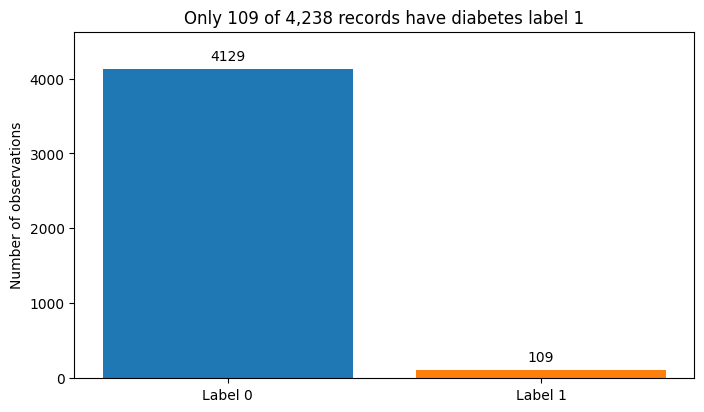

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(["Label 0", "Label 1"], class_counts.to_numpy(), color=["tab:blue", "tab:orange"])
ax.bar_label(bars, padding=4)
ax.set_ylim(0, class_counts.max() * 1.12)
ax.set_ylabel("Number of observations")
ax.set_title("Only 109 of 4,238 records have diabetes label 1")
plt.show()

The next plots compare input distributions within each class. Each class is
normalized separately, making the small positive class visible. Missing values
are omitted from these plots; model preprocessing below retains the observations.
The CSV does not include a data dictionary, so feature units and collection
details should be confirmed from its original source before a real application.

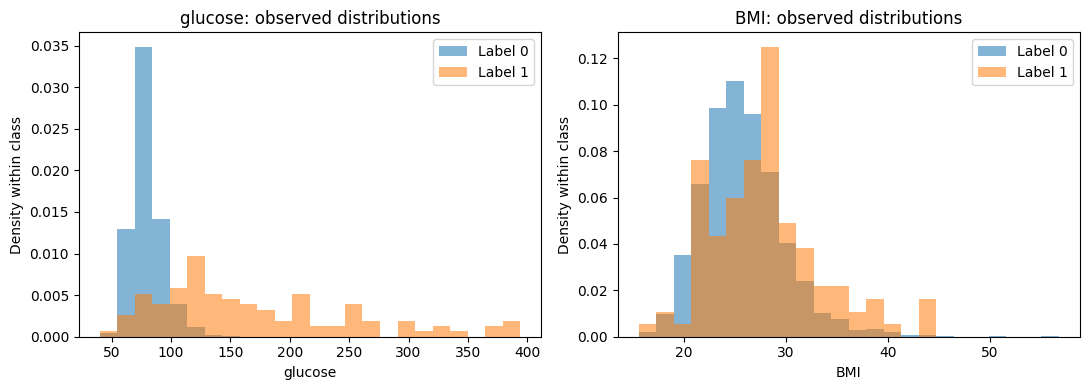

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ["glucose", "BMI"]):
    bins = np.linspace(df[feature].min(), df[feature].max(), 25)
    for label, color in [(0, "tab:blue"), (1, "tab:orange")]:
        values = df.loc[y == label, feature].dropna()
        ax.hist(values, bins=bins, density=True, alpha=0.55, color=color, label=f"Label {label}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density within class")
    ax.set_title(f"{feature}: observed distributions")
    ax.legend()
fig.tight_layout()
plt.show()

## 3. From a weighted score to a probability

The model learns seven feature weights and an intercept. After preprocessing the
inputs, it forms a weighted score:

$$z = b_0 + b_1\tilde{x}_1 + \cdots + b_7\tilde{x}_7.$$

The sigmoid converts this score into the estimated probability of label 1:

$$p(y=1\mid X) = \frac{1}{1+e^{-z}}.$$

The tildes indicate imputed, standardized features rather than raw measurements.
At the usual threshold of 0.5, a probability above 0.5 gives class 1 and a
probability below 0.5 gives class 0. The table later in this lesson makes a
threshold's equality rule explicit. A probability is a model estimate of an
outcome; model accuracy is measured by comparing many predictions with labels.

The classifier learns using log loss with regularization, rather than the squared
error fitting objective used by ordinary linear regression. Log loss penalizes
confident predictions of the wrong class strongly.

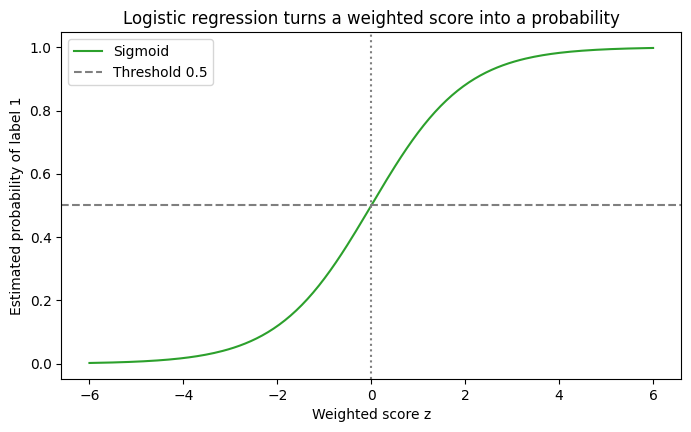

In [7]:
score_grid = np.linspace(-6, 6, 200)
probability_grid = 1 / (1 + np.exp(-score_grid))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(score_grid, probability_grid, color="tab:green", label="Sigmoid")
ax.axhline(0.5, color="tab:gray", linestyle="--", label="Threshold 0.5")
ax.axvline(0, color="tab:gray", linestyle=":")
ax.set_xlabel("Weighted score z")
ax.set_ylabel("Estimated probability of label 1")
ax.set_title("Logistic regression turns a weighted score into a probability")
ax.legend()
plt.show()

## 4. Split before learning preprocessing statistics

We hold out 25% of the observations. `stratify=y` approximately preserves the
positive-class proportion, which matters when only 109 records are positive.
`random_state=42` makes the split repeatable.

The revised split contains 3,178 training records and 1,060 test records, with
82 positives in training and 27 positives in testing. We keep every row.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

split_summary = pd.DataFrame(
    {
        "Training observations": y_train.value_counts().reindex([0, 1], fill_value=0),
        "Test observations": y_test.value_counts().reindex([0, 1], fill_value=0),
    }
)
split_summary.index.name = "Recorded diabetes label"
print(f"Training shape: {X_train.shape}; test shape: {X_test.shape}")
split_summary

Training shape: (3178, 7); test shape: (1060, 7)


,Training observations,Test observations
Recorded diabetes label,,
0,3096,1033
1,82,27


## 5. Fit a preprocessing-and-model pipeline

The pipeline applies three steps in order:

1. `SimpleImputer(strategy="median")` fills a missing input with that feature's
   median learned from the training set. The known target labels are kept as given.
2. `StandardScaler()` centers and scales each imputed input using training-set
   means and standard deviations. The regularized model then sees comparable scales.
3. `LogisticRegression(max_iter=1000)` learns the classifier. A larger iteration
   limit allows room for convergence; it is not a promise of better predictions.

`model.fit(X_train, y_train)` learns all three steps on training data.
`model.predict(X_test)` reuses those fitted transformations. Learning imputation
or scaling statistics from the entire dataset would let the test set influence
the training process.

We also fit `DummyClassifier(strategy="most_frequent")`, which always predicts
the most common training label, zero. It provides a meaningful comparison for
the apparently high accuracy of an imbalanced problem.

In [9]:
model = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)
model.fit(X_train, y_train)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None


## 6. Class predictions and probabilities

`predict` returns class labels. `predict_proba` returns one probability column
per class, in the order shown by `model.classes_`. With classes `[0, 1]`, column
1 contains the estimated probability of label 1. Inputs are supplied using the
same seven feature columns in the same order as training.

For this classifier, `model.score(X_test, y_test)` returns **accuracy**. In the
linear regression notebook, the same method name returned **R²**. The estimator
determines the meaning of `score`.

In [10]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
baseline_pred = baseline.predict(X_test)

print(f"Probability column order: {model.classes_}")
print(f"Classifier score (accuracy): {model.score(X_test, y_test):.4f}")

prediction_examples = pd.DataFrame(
    {"Actual label": y_test, "Probability of label 1": y_probability, "Predicted label": y_pred},
    index=X_test.index,
)
prediction_examples.head(8).round(4)

Probability column order: [0 1]
Classifier score (accuracy): 0.9906


,Actual label,Probability of label 1,Predicted label
1730,0,0.0117,0
3928,0,0.0091,0
2872,0,0.0231,0
3465,0,0.0040,0
701,0,0.0037,0
3213,0,0.0052,0
2248,0,0.0021,0
124,0,0.0456,0


## 7. Evaluate the positive class as well as overall accuracy

With class 1 treated as positive:

- **TP:** actual 1, predicted 1; a detected positive record.
- **FN:** actual 1, predicted 0; a missed positive record.
- **FP:** actual 0, predicted 1; a false positive.
- **TN:** actual 0, predicted 0; a correctly identified negative record.

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$

$$\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN}$$

$$F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}
{\text{Precision}+\text{Recall}}$$

Accuracy asks how often the predicted label is correct overall. Precision asks
how many positive predictions are correct. Recall asks how many actual positives
are detected. F1 combines positive-class precision and recall. Balanced accuracy
averages the recall of class 0 and class 1, giving both classes equal weight.

If a model never predicts class 1, positive-class precision is undefined. We use
`zero_division=0` to report it as zero consistently with zero positive recall.

In [11]:
def classification_metrics(y_true, predicted):
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "Precision (class 1)": precision_score(y_true, predicted, zero_division=0),
        "Recall (class 1)": recall_score(y_true, predicted, zero_division=0),
        "F1 (class 1)": f1_score(y_true, predicted, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, predicted),
    }

results = pd.DataFrame(
    [classification_metrics(y_test, baseline_pred), classification_metrics(y_test, y_pred)],
    index=["Always predict 0", "Logistic regression"],
)
results.round(4)

,Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),Balanced accuracy
Always predict 0,0.9745,0.0,0.0000,0.0000,0.5000
Logistic regression,0.9906,1.0,0.6296,0.7727,0.8148


In [12]:
print(
    classification_report(
        y_test, y_pred, labels=[0, 1], target_names=["Label 0", "Label 1"],
        digits=3, zero_division=0,
    )
)

              precision    recall  f1-score   support

     Label 0      0.990     1.000     0.995      1033
     Label 1      1.000     0.630     0.773        27

    accuracy                          0.991      1060
   macro avg      0.995     0.815     0.884      1060
weighted avg      0.991     0.991     0.990      1060



In the report, **support** is the number of actual observations in each class.
The **macro average** gives the two classes equal weight; the **weighted average**
uses their support, so the many label-0 records dominate that average.

The confusion matrix below uses **rows for actual labels** and **columns for
predicted labels**. At the usual operating threshold on this split, the model
detects 17 of 27 positives and misses 10. It makes no false-positive predictions
on this test set, giving precision of 1.0 from only 17 positive predictions. That
does not establish perfect precision on future observations.

Overall accuracy is about 99.06%, compared with 97.45% for always predicting zero.
Positive recall is about 62.96%, so the high accuracy still coexists with missed
positive cases. There are only 27 positives in this held-out set; results can
vary substantially between samples.

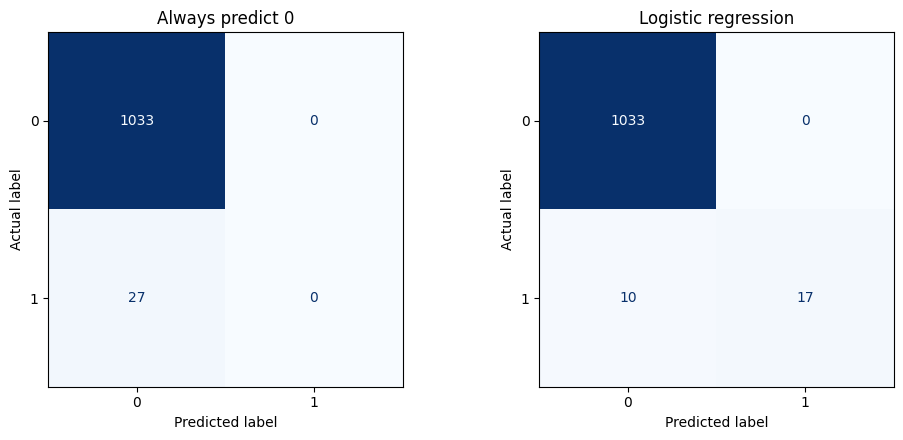

Detected positives: 17 of 27; missed positives: 10
Positive precision: 100.0%; positive recall: 63.0%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, predicted, title in [
    (axes[0], baseline_pred, "Always predict 0"),
    (axes[1], y_pred, "Logistic regression"),
]:
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
fig.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print(f"Detected positives: {tp} of {tp + fn}; missed positives: {fn}")
print(f"Positive precision: {tp / (tp + fp):.1%}; positive recall: {tp / (tp + fn):.1%}")

## 8. Optional: see the precision-recall tradeoff

The curve uses the estimated label-1 probabilities to show precision and recall
at different thresholds. **Average precision (AP)** summarizes this ranking:
higher is better on the same evaluated data. Its reference for a constant score
is the positive-class proportion, approximately 2.55% in this test set.

The curve describes performance across thresholds. The reported classification
metrics above use the classifier's usual threshold. Choose an operating threshold
using a validation set or cross-validation within training data, together with
the intended cost of missed positives and false positives. Keep the final test
set for evaluation rather than using it to select a threshold.

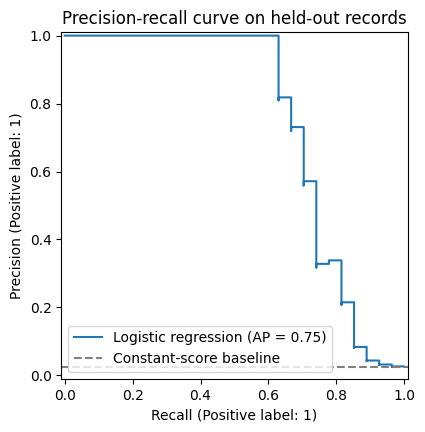

Average precision: 0.748


In [14]:
average_precision = average_precision_score(y_test, y_probability)
fig, ax = plt.subplots(figsize=(8, 4.5))
PrecisionRecallDisplay.from_predictions(
    y_test, y_probability, name="Logistic regression", ax=ax
)
ax.axhline(y_test.mean(), color="tab:gray", linestyle="--", label="Constant-score baseline")
ax.set_title("Precision-recall curve on held-out records")
ax.legend(loc="lower left")
plt.show()
print(f"Average precision: {average_precision:.3f}")

Here is a separate toy example of thresholding. We explicitly assign class 1
when `probability >= threshold`. Lowering the threshold marks more records as
positive; some additional flags may be correct and others may be false positives.
This demonstrates the rule without selecting a new threshold from the test data.

In [15]:
toy_probabilities = np.array([0.10, 0.35, 0.80])
threshold_examples = pd.DataFrame(
    {
        "Probability of label 1": toy_probabilities,
        "Class at threshold 0.50": (toy_probabilities >= 0.50).astype(int),
        "Class at threshold 0.30": (toy_probabilities >= 0.30).astype(int),
    }
)
threshold_examples

,Probability of label 1,Class at threshold 0.50,Class at threshold 0.30
0,0.10,0,0
1,0.35,0,1
2,0.80,1,1


## 9. Optional: investigate reliance on glucose using training folds

Glucose is strongly associated with the recorded diabetes label. The CSV alone
does not tell us whether it helped define that label, or whether it was available
before an intended future prediction. This requires the source documentation.

We compare the model with and without glucose using the same five stratified
**training-data** folds. Each fold fits its own imputer, scaler, and classifier.
This sensitivity check examines reliance on a feature; it does not prove that
leakage occurred. The main model and held-out test results above stay fixed.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sensitivity_rows = []
for description, columns in [
    ("All seven features", feature_columns),
    ("Without glucose", [column for column in feature_columns if column != "glucose"]),
]:
    scores = cross_validate(
        model, X_train[columns], y_train, cv=cv,
        scoring={"average_precision": "average_precision", "recall": "recall"},
        error_score="raise",
    )
    sensitivity_rows.append(
        {
            "Inputs": description,
            "Mean validation AP": scores["test_average_precision"].mean(),
            "Validation AP std": scores["test_average_precision"].std(),
            "Mean validation recall": scores["test_recall"].mean(),
        }
    )
sensitivity_results = pd.DataFrame(sensitivity_rows).set_index("Inputs")
sensitivity_results.round(3)

,Mean validation AP,Validation AP std,Mean validation recall
Inputs,,,
All seven features,0.674,0.123,0.463
Without glucose,0.097,0.050,0.000


With this dataset and split, removing glucose greatly lowers validation average
precision, and the no-glucose model predicts no positives at its usual threshold
in these folds. This is evidence that the model relies heavily on glucose.

With glucose, mean validation recall is about 46%, while held-out test recall is
about 63%. The small number of positives makes it important to inspect variation
between folds and avoid treating one test score as a complete assessment.

## Study questions

1. How many observations, features, and targets are in the chosen input/target arrays?
2. Why can always predicting zero achieve about 97% accuracy here?
3. In the original matrix `[[930, 2], [12, 13]]`, which number counts missed positives?
4. Why is original positive recall `13 / (13 + 12)`?
5. Why is original positive precision `13 / (13 + 2)`?
6. What does `predict_proba` return that `predict` does not?
7. A probability is 0.35: what class does the toy rule give at thresholds 0.5 and 0.3?
8. Why do we learn medians and scaling statistics from training data only?
9. Why does a large accuracy score need a majority-class baseline and a confusion matrix?
10. What source information would you need before claiming this predicts future diabetes?

References: [Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression),
[confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html),
and [pipelines](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).